# Extended Figure 4 — fresh-frozen vs FFPE, sequencing QC and high-confidence benchmark

Companion to Figure 3 for the two patient samples sequenced both fresh-frozen (**FF**) and
**FFPE** on Illumina WGS. Panel A is operational sequencing QC; panels B–D benchmark FFPE
against FF inside the GIAB high-confidence regions, with FF as truth: **TP** called in both,
**FN** in FF only, **FP** in FFPE only.

| Panel | Content |
|-------|---------|
| **A** | REDUX overview — raw yield, unmapping, deduplication/consensus, post-REDUX yield |
| **B** | SNV and indel Venn diagrams per patient (FF vs FFPE) |
| **C** | SNV mutational spectrum (SBS-96) and VAF distribution of the TP / FP / FN sets |
| **D** | Indel mutational spectrum (COSMIC ID-83) and VAF distribution of the TP / FP / FN sets |

Point the Configuration cell at other runs — or your own oncoanalyser output — and run all
cells; see **Data access** below.

## Data access

Every input below is public **oncoanalyser** output, published in two Google Cloud Storage
buckets. Nothing else is needed to reproduce this figure.

| Bucket | Content | Size |
| --- | --- | --- |
| `gs://hartwig-oapaper-celllines` | 5 cell lines x 3 sequencing platforms, WGS and targeted panel | 36 GB |
| `gs://hartwig-oapaper-patients` | 2 consented patients, fresh-frozen and FFPE WGS, targeted panel | — |

### Folder scheme

Every pipeline run has one folder, built from the same fields in the same order —
**sample, modality, platform, aligner, run type, pipeline**:

```text
gs://hartwig-oapaper-celllines/<sample>/<modality>/<platform>/<aligner>/<run type>/<pipeline>/
gs://hartwig-oapaper-patients/<sample>/<modality>/<preservation>/<platform>/<aligner>/<run type>/<pipeline>/

<sample>        COLO829 | HCC1187 | HCC1395 | HCC1954 | HG008      cell lines
                H00005238 | H00006429                              patients
<modality>      wgs | panel                 panel = HMF oncopanel v3, Illumina only
<preservation>  ff | ffpe                   patients only
<platform>      illumina_novaseq6000 | roche_sbx | ultima_ug100
<aligner>       bwa
<run type>      tn = tumour/normal | to = tumour-only
<pipeline>      oa3 = oncoanalyser 3.x
```

So COLO829, Illumina WGS, tumour/normal is:

```text
gs://hartwig-oapaper-celllines/COLO829/wgs/illumina_novaseq6000/bwa/tn/oa3/
```

Inside `oa3/` are the oncoanalyser output directories exactly as the pipeline writes them —
`alignments/`, `bamtools/`, `purple/`, `sage/`, `linx/`, `sigs/`, `logs/`, ... — with **no**
`results/<subject>` level in between.

Sample names inside a run are *not* uniform: tumours are `<sample>T`, but normals are
`<sample>R` for COLO829, HG008 and the patients and `<sample>BL` for HCC1187/HCC1395/HCC1954,
and the Illumina COLO829 WGS run uses `COLO829v012T` / `COLO829v012R` throughout. Nothing
hard-codes them — every notebook reads the real names out of `alignments/` and `purple/`.

Browse it with:

```bash
gsutil ls gs://hartwig-oapaper-celllines/
gsutil ls gs://hartwig-oapaper-celllines/COLO829/wgs/illumina_novaseq6000/bwa/tn/oa3/
```

### What this notebook reads (~40 MB)

Six run folders for the two patients: FF tumour/normal, FFPE tumour/normal, and the FFPE
tumour-only run that holds the FFPE tumour's own alignments and QC.

```text
gs://hartwig-oapaper-patients/<patient>/wgs/ff/illumina_novaseq6000/bwa/tn/oa3/     FF arm
gs://hartwig-oapaper-patients/<patient>/wgs/ffpe/illumina_novaseq6000/bwa/tn/oa3/   FFPE arm
gs://hartwig-oapaper-patients/<patient>/wgs/ffpe/illumina_novaseq6000/bwa/to/oa3/   FFPE tumour QC

  logs/<patient>_<sample>.redux.command.log           panel A   unmapping / duplicate stats
  bamtools/<sample>/<sample>.bam_metric.summary.tsv   panel A   yield, coverage, uniformity
  purple/<tumour>.purple.somatic.vcf.gz               panels B-D
```

Panel A reads both tumour and normal; panels B–D read the tumour PURPLE VCF only. The FFPE
tumour/normal calling run reuses alignments produced in a separate tumour-only run, so its own
`alignments/` and `bamtools/` folders are absent — that is what `REDUX_SOURCES` in the
Configuration cell redirects, and why the FFPE normal row reuses the FF normal.

The **GIAB high-confidence BED** is downloaded straight from the NIST GIAB FTP site over
https (10 MB, no credentials) — it is not part of either bucket. It is the GRCh38, chr-prefixed
NISTv3.3.2 HG001 high-confidence region set.

**The patient bucket is not yet public.** This notebook needs read access to
`gs://hartwig-oapaper-patients`; an unreadable run is reported and skipped rather than fatal.

### Option 1 — read straight from the bucket (the default; nothing to download first)

Leave the `gs://` values in the Configuration cell as they are and run all cells. Only the
files listed above are staged, into `data/`, and re-used on every later run — delete that
directory to re-fetch. You need the
[Google Cloud SDK](https://cloud.google.com/sdk/docs/install) on `PATH`, authenticated once:

```bash
gcloud auth login      # any Google account works; the buckets are public, this only sets the billing/quota project
```

### Option 2 — copy the data down first, then work offline

Mirror only the run folders this notebook needs (sizes above), then repoint the
Configuration cell at the copy:

```bash
DEST=~/oapaper-data          # anywhere with enough free space
for S in H00005238 H00006429; do
  for SUB in wgs/ff/illumina_novaseq6000/bwa/tn \
             wgs/ffpe/illumina_novaseq6000/bwa/tn \
             wgs/ffpe/illumina_novaseq6000/bwa/to; do
    gcloud storage rsync -r \
      gs://hartwig-oapaper-patients/$S/$SUB/oa3 \
      $DEST/$S/$SUB/oa3
  done
done
```

Then, in the Configuration cell:

```python
PATIENTS_ROOT = "/absolute/path/to/oapaper-data"   # the $DEST above
```

Local paths must be **absolute** — `~` is not expanded, so `~/oapaper-data` fails with
`FileNotFoundError`. `gcloud storage rsync` is resumable: re-run it after an interruption.

### Option 3 — run it on your own oncoanalyser output

Point the Configuration cell at any oncoanalyser 3.x run directory, local or `gs://`. The
only requirement is that the directory contains the tool sub-folders listed above; the
sample names are read from the files themselves, so they do not have to match ours.


## 1 · Configuration

In [24]:
from pathlib import Path
from collections import OrderedDict

# ============================================================================
# CONFIGURATION — edit these to point at your own oncoanalyser output.
#
# Each arm is a {patient id: run folder} map. A run folder is one oncoanalyser
# output directory — local path or gs:// URI — holding purple/, bamtools/ and
# logs/ directly (no results/<subject> level). patient_run() builds them from
# the scheme described in Data access above.
# ============================================================================
PATIENTS_ROOT   = "gs://hartwig-oapaper-patients"   # or an absolute path to a local copy
PATIENT_SAMPLES = ["H00005238", "H00006429"]
PLATFORM        = "illumina_novaseq6000"

def patient_run(sample, preservation, run_type, platform=PLATFORM):
    """<PATIENTS_ROOT>/<sample>/wgs/<ff|ffpe>/<platform>/bwa/<tn|to>/oa3"""
    return (f"{str(PATIENTS_ROOT).rstrip('/')}/{sample}/wgs/{preservation}"
            f"/{platform}/bwa/{run_type}/oa3")

def runs(preservation, run_type):
    return {s: patient_run(s, preservation, run_type) for s in PATIENT_SAMPLES}

MODALITIES = OrderedDict([
    ("FF",   {"runs": runs("ff", "tn"),   "color": "#22876B", "label": "Fresh-frozen (TN)"}),
    ("FFPE", {"runs": runs("ffpe", "tn"), "color": "#754275", "label": "FFPE (TN)"}),
])
# Panel A reads the REDUX log and bamtools metrics, which for the FFPE tumour live in a separate
# tumour-only run; the FFPE normal reuses the FF normal, so that row matches FF's normal row.
REDUX_SOURCES = OrderedDict([
    ("FF",   {"T": runs("ff", "tn"),   "N": runs("ff", "tn")}),
    ("FFPE", {"T": runs("ffpe", "to"), "N": runs("ff", "tn")}),
])
# GIAB high-confidence regions (GRCh38, chr-prefixed) — panels B-D are restricted to these.
# Downloaded over https from the NIST GIAB FTP site; no cloud credentials needed.
HIGHCONF_BED = ("https://ftp-trace.ncbi.nlm.nih.gov/ReferenceSamples/giab/release/NA12878_HG001"
                "/NISTv3.3.2/GRCh38/HG001_GRCh38_GIAB_highconf_CG-IllFB-IllGATKHC-Ion-10X-SOLID"
                "_CHROM1-X_v.3.3.2_highconf_nosomaticdel_noCENorHET7.bed")
# ============================================================================

VAF_MIN = 0.10                 # inclusion gate: keep a variant if it reaches this AF on >=1 arm
TUMOR_SUFFIXES  = ("T",)
NORMAL_SUFFIXES = ("R", "BL")
BAM_SUMMARY = "bam_metric.summary.tsv"

CACHE_ROOT = Path("data") / "extended_figure_4"
EXPORT_DIR = Path("figures"); EXPORT_DIR.mkdir(parents=True, exist_ok=True)
for _m, _cfg in MODALITIES.items():
    print(f"{_m:5s} {next(iter(_cfg['runs'].values()))}")
print("Truth arm:", list(MODALITIES)[0], "| VAF gate:", VAF_MIN)

FF    gs://hartwig-oapaper-patients/H00005238/wgs/ff/illumina_novaseq6000/bwa/tn/oa3
FFPE  gs://hartwig-oapaper-patients/H00005238/wgs/ffpe/illumina_novaseq6000/bwa/tn/oa3
Truth arm: FF | VAF gate: 0.1


## 2 · Locating pipeline output

Turns each `{patient: run folder}` map from the Configuration cell into the sample names the
loaders need, and provides the local / `gs://` / `https://` read helpers. Nothing is downloaded
here.

In [25]:
import subprocess, re, hashlib
from pathlib import Path

# ---- IO: identical behaviour for local paths, gs:// URIs and https:// downloads ---------------
# Every gsutil call goes through _gsutil, which returns None when the target simply does not exist
# and raises on anything else (auth, permissions, typo'd bucket). A silent [] on a failed listing
# is what makes a missing-data problem look like an empty-run problem.
_MISSING = ("matched no objects", "no urls matched", "404")

def _is_remote(p):
    return str(p).startswith("gs://")

def _gsutil(*args):
    r = subprocess.run(["gsutil", *map(str, args)], capture_output=True, text=True)
    if r.returncode != 0:
        err = r.stderr.strip()
        if any(m in err.lower() for m in _MISSING):
            return None
        raise RuntimeError(f"gsutil {' '.join(map(str, args))} failed:\n{err}")
    return r.stdout

_GLOB_CACHE = {}   # listings are memoised for the session; clear it if a run folder changes

def _glob(folder, pattern, dirs_only=True):
    # Entries matching folder/pattern, without a trailing slash. '*' never crosses a '/'.
    key = (str(folder).rstrip("/"), pattern, dirs_only)
    if key not in _GLOB_CACHE:
        _GLOB_CACHE[key] = _glob_uncached(*key)
    return _GLOB_CACHE[key]

def _glob_uncached(folder, pattern, dirs_only):
    if _is_remote(folder):
        out = _gsutil("ls", "-d", f"{str(folder).rstrip('/')}/{pattern}")
        hits = [l for l in (out or "").splitlines() if l.strip()]
        if dirs_only:
            hits = [h for h in hits if h.endswith("/")]
        return sorted(h.rstrip("/") for h in hits)
    return sorted(str(p) for p in Path(folder).glob(pattern) if p.is_dir() or not dirs_only)

def _cat(src):
    if _is_remote(src):
        out = _gsutil("cat", str(src))
        if out is None:
            raise FileNotFoundError(src)
        return out
    return Path(src).read_text()

def _fetch(src, dest):
    # Copy one file into the local cache. Returns None (not an exception) when the source is
    # absent, so a run that skipped a step degrades to a blank panel instead of a crash.
    dest = Path(dest)
    if dest.exists():
        return dest
    dest.parent.mkdir(parents=True, exist_ok=True)
    if str(src).startswith(("http://", "https://")):
        # public reference files (the GIAB BED) are plain downloads, no cloud credentials needed
        import urllib.error, urllib.request
        try:
            urllib.request.urlretrieve(str(src), dest)
        except (urllib.error.URLError, OSError) as e:
            print(f"WARN: could not download {src}: {e}")
            return None
        return dest
    if _is_remote(src):
        if _gsutil("cp", str(src), str(dest)) is None:
            return None
    else:
        if not Path(src).exists():
            return None
        import shutil; shutil.copy(Path(src), dest)
    return dest

def cache_dir(root, folder, *parts):
    """Local cache path, keyed on the source folder.

    Two runs of the same arm live in different directories, so re-pointing a folder never
    silently reuses the previous run's downloaded files.
    """
    src = str(folder).rstrip("/")
    tail = [p for p in src.split("//")[-1].split("/") if p][-6:]   # readable, still unambiguous
    label = re.sub(r"[^A-Za-z0-9]+", "-", "-".join(tail)).strip("-")
    return Path(root, f"{label}-{hashlib.sha1(src.encode()).hexdigest()[:6]}", *parts)

def _classify(sample):
    # Tumour vs normal from the sample-name suffix (BL checked before R: "...BL" also ends in 'L').
    for suf in NORMAL_SUFFIXES:
        if sample.endswith(suf):
            return "N"
    for suf in TUMOR_SUFFIXES:
        if sample.endswith(suf):
            return "T"
    return None

# ---- Subject discovery ------------------------------------------------------------------------
# In this layout a run folder *is* the subject directory: purple/, alignments/, bamtools/, logs/
# and the rest sit directly inside it, with no results/<subject> level. Sample names are still
# read out of the output rather than assumed, so runs whose samples are named differently
# (COLO829v012T, HCC1187BL, ...) need no configuration. PURPLE output is the marker, because
# runs started from pre-existing BAMs do not always republish an alignments/ folder.
_PURITY_SUFFIX = ".purple.purity.tsv"

def find_tumour(base):
    """Tumour sample name of one run folder, from <base>/purple/<tumour>.purple.purity.tsv.

    Returns None when the run simply has no PURPLE output, and raises when the location cannot
    be read at all (no credentials, no access, wrong bucket). Callers turn that into a single
    warning for the whole arm, so a permissions problem is never mistaken for an empty run.
    """
    hits = _glob(base, f"purple/*{_PURITY_SUFFIX}", dirs_only=False)
    return hits[0].rsplit("/", 1)[-1][:-len(_PURITY_SUFFIX)] if hits else None

def _unreadable(base, err):
    print(f"WARN: cannot read {base}\n      {str(err).strip().splitlines()[-1]}")

def discover_subjects(runs):
    """{sid: (tumour_sample, base)} for a {sid: run folder} map, in configured order."""
    found = {}
    for sid, base in runs.items():
        try:
            tumor = find_tumour(base)
        except RuntimeError as e:      # the whole location is unreadable, not just this run
            _unreadable(base, e)
            break
        if tumor is None:
            print(f"WARN: no PURPLE output under {base}/purple/ -- skipping {sid}")
            continue
        found[sid] = (tumor, base)
    return found

def run_samples(base):
    """[sample, ...] with bamtools output in one run folder; [] when there is none."""
    try:
        return sorted(h.rsplit("/", 1)[-1] for h in _glob(base, "bamtools/*"))
    except RuntimeError as e:
        _unreadable(base, e)
        return []

print("path helpers ready")

path helpers ready


## 3 · Plotting style

In [26]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import Patch

mpl.rcParams.update({
    "figure.dpi": 120, "savefig.dpi": 300,
    "font.family": "sans-serif", "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "font.size": 12.5, "axes.titlesize": 14, "axes.labelsize": 12.5, "axes.titleweight": "bold",
    "xtick.labelsize": 10.9, "ytick.labelsize": 10.9, "legend.fontsize": 10.9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.linewidth": 0.8, "legend.frameon": False,
    "svg.fonttype": "none", "pdf.fonttype": 42, "ps.fonttype": 42,
})

# COSMIC SBS 6-class palette
SBS_CLASSES = ["C>A", "C>G", "C>T", "T>A", "T>C", "T>G"]
SBS_COLORS = {"C>A": "#03BCEE", "C>G": "#000000", "C>T": "#E32926",
              "T>A": "#CACACA", "T>C": "#A1CE63", "T>G": "#EDBFC2"}

# Panel A
UNMAP_COLORS = OrderedDict([("high depth", "#D1495B"), ("soft-clip", "#E08214"),
                            ("chimeric", "#2C6FBB")])
DUP_CORAL = "#E4572E"
TN_OFFSET, TN_H, HATCH = 0.19, 0.34, "////"
TN_ROWS = (("T", TN_OFFSET, None), ("N", -TN_OFFSET, HATCH))

def fmt(n):
    n = float(n)
    return f"{n/1000:.1f}k" if n >= 1000 else f"{n:.0f}"

def human(n):
    n = float(n)
    for unit, div in (("B", 1e9), ("M", 1e6), ("k", 1e3)):
        if abs(n) >= div:
            return f"{n/div:.2f}{unit}"
    return f"{n:.0f}"

## 4 · Load REDUX QC metrics (panel A)

Per arm, patient and tissue (tumour / matched normal): the bamtools `bam_metric.summary.tsv` and the
REDUX run log. REDUX re-flags rather than deletes reads, so raw reads = total reads and post-REDUX
reads = those still mapped; raw coverage and bases are grossed back up as post ÷ (1 − f), with f the
unmapped fraction, which makes the raw→post drop equal the unmapping %. No variant content is read.

In [27]:
import numpy as np
import pandas as pd

SUBJECTS = {m: discover_subjects(MODALITIES[m]["runs"]) for m in MODALITIES}
PATIENTS = [s for s in PATIENT_SAMPLES if any(s in SUBJECTS[m] for m in MODALITIES)]
TRUTH, TEST = list(MODALITIES)
print("patients:", PATIENTS)

# ---- REDUX run-log parsing (tolerant of missing keys) ------------------------------------------
_REASON_LABEL = {"depth": "high depth", "softClip": "soft-clip", "chimeric": "chimeric"}

def parse_log_stats(text):
    s = {}
    m = re.search(r"reasons\(([^)]*)\)", text)        # reasons(depth=.. softClip=.. chimeric=..)
    if m:
        reasons = {}
        for kv in m.group(1).split():
            k, _, v = kv.partition("=")
            if v.isdigit():
                reasons[_REASON_LABEL.get(k, k)] = int(v)
        s["unmap_reasons"] = reasons
    m = re.search(r"totalReads\((\d+)\) duplicates\((\d+)\) dupGroups\((\d+)\) umiGroups\((\d+)\)", text)
    if m:
        s.update(total_reads=int(m.group(1)), duplicates=int(m.group(2)),
                 dup_groups=int(m.group(3)), umi_groups=int(m.group(4)))
    if re.search(r"duplicate marking:\s*disabled", text):
        s["dedup_disabled"] = True
    return s

def fetch_log_stats(sid, sample, base, dest):
    # Cache only the handful of relevant REDUX log lines, then parse them. {} if there is no log.
    cache = Path(dest) / f"{sample}.logstats.txt"
    if not cache.exists():
        try:
            txt = _cat(f"{base}/logs/{sid}_{sample}.redux.command.log")
        except Exception:
            return {}
        keep = [l for l in txt.splitlines()
                if ("unmapped stats:" in l or "stats: totalReads" in l
                    or "unmapping regions from" in l or "duplicate marking:" in l)]
        cache.parent.mkdir(parents=True, exist_ok=True)
        cache.write_text("\n".join(keep))
    return parse_log_stats(cache.read_text())

# ---- bamtools yield / coverage summary ---------------------------------------------------------
_SUMMARY_MAP = OrderedDict([
    ("TotalReads", "total_reads"), ("MeanCoverage", "mean_cov"),
    ("MedianCoverage", "median_cov"), ("MadCoverage", "mad_cov"),
    ("TotalRegionBases", "total_region_bases"),
    ("DuplicatePercent", "dup_pct"), ("UnmappedPercent", "unmapped_pct"),
])

def fetch_summary_stats(sample, base, dest):
    path = _fetch(f"{base}/bamtools/{sample}/{sample}.{BAM_SUMMARY}", Path(dest) / f"{sample}.summary.tsv")
    if path is None:
        print(f"WARN: no bamtools summary for {sample}")
        return {}
    df = pd.read_csv(path, sep="\t"); row = df.iloc[0]
    out = {key: float(row[col]) for col, key in _SUMMARY_MAP.items() if col in df.columns}
    if out.get("total_region_bases") and out.get("mean_cov"):
        out["total_bases_gb"] = out["mean_cov"] * out["total_region_bases"] / 1e9
    med = out.get("median_cov")
    out["uniformity"] = (out["mad_cov"] / med) if (med and out.get("mad_cov") is not None) else np.nan
    return out

def load_redux_qc(arm):
    # [{patient, "T": rec|None, "N": rec|None}, ...]; rec = {sample, log, summary}. Tumour and
    # normal come from their own source run (REDUX_SOURCES), discovered via that run's bamtools/.
    src = REDUX_SOURCES[arm]
    groups = []
    for sid in PATIENTS:
        g = {"patient": sid, "T": None, "N": None}
        for tis in ("T", "N"):
            base = src[tis].get(sid)
            if base is None:
                continue
            dest = cache_dir(CACHE_ROOT, base, "redux_qc", sid)
            sample = next((s for s in run_samples(base) if _classify(s) == tis), None)
            if not sample:
                print(f"WARN: no {tis} sample with bamtools output under {base}")
                continue
            g[tis] = {"sample": sample, "log": fetch_log_stats(sid, sample, base, dest),
                      "summary": fetch_summary_stats(sample, base, dest)}
        if g["T"] or g["N"]:
            groups.append(g)
    return groups

def _yield_vals(rec):
    # Split per-sample yield into pre-REDUX (raw, derived) and post-REDUX (measured).
    sm, lg = rec["summary"], rec["log"]
    T = sm.get("total_reads"); cov = sm.get("mean_cov"); base = sm.get("total_bases_gb")
    U = sum(lg.get("unmap_reasons", {}).values()) if lg.get("unmap_reasons") else 0
    keep = 1.0 - ((U / T) if (T and U) else 0.0)
    pre  = {"reads": T, "cov": (cov / keep) if (cov and keep) else cov,
            "bases": (base / keep) if (base and keep) else base}
    post = {"reads": (T * keep) if T else None, "cov": cov, "bases": base,
            "unif": sm.get("uniformity")}
    return pre, post

def _unmap_frac(rec):
    tot = rec["summary"].get("total_reads")
    u = sum(rec["log"].get("unmap_reasons", {}).values()) if rec["log"].get("unmap_reasons") else None
    return (u / tot) if (tot and u is not None) else float("nan")

REDUX_QC = {arm: load_redux_qc(arm) for arm in MODALITIES}
for arm, groups in REDUX_QC.items():
    for g in groups:
        for tis in ("T", "N"):
            r = g[tis]
            if not r:
                continue
            _, post = _yield_vals(r)
            print(f"{arm:5s} {g['patient']:10s} {tis} [{r['sample']:>12s}] "
                  f"log={'yes' if r['log'] else 'no':<3s} reads={human(post['reads'] or 0):>7s} "
                  f"unmap={_unmap_frac(r):.2%} dup={r['summary'].get('dup_pct', float('nan')):.1%}")

patients: ['H00005238', 'H00006429']
WARN: no T sample with bamtools output under gs://hartwig-oapaper-patients/H00005238/wgs/ffpe/illumina_novaseq6000/bwa/to/oa3
WARN: no T sample with bamtools output under gs://hartwig-oapaper-patients/H00006429/wgs/ffpe/illumina_novaseq6000/bwa/to/oa3
FF    H00005238  T [  H00005238T] log=yes reads=  1.92B unmap=0.98% dup=13.7%
FF    H00005238  N [  H00005238R] log=yes reads=927.17M unmap=1.25% dup=12.6%
FF    H00006429  T [  H00006429T] log=yes reads=  3.33B unmap=0.71% dup=16.1%
FF    H00006429  N [  H00006429R] log=yes reads=767.61M unmap=0.83% dup=7.3%
FFPE  H00005238  N [  H00005238R] log=yes reads=927.17M unmap=1.25% dup=12.6%
FFPE  H00006429  N [  H00006429R] log=yes reads=767.61M unmap=0.83% dup=7.3%


## 5 · Load high-confidence per-variant data (panels B–D)

The GIAB high-confidence BED is fetched once and indexed per chromosome. Per arm and patient, the
cached PURPLE somatic VCF is read to `key -> (tumour VAF, mutation channel)` for every PASS SNV and
indel inside those regions — channel = SBS-96 (from the INFO `TNC`) for SNVs and COSMIC ID-83
(from the SAGE `REP_C` / `REP_S` / `RC_MH` annotations) for indels. Matching FF↔FFPE by
`chrom:pos:ref:alt` then gives the TP / FN / FP sets behind panels B–D.

In [28]:
import gzip

_COMP = {"A": "T", "T": "A", "C": "G", "G": "C", "N": "N"}

def _rc(s):
    return "".join(_COMP[b] for b in reversed(s))

# ---- high-confidence BED: chrom -> (sorted starts, ends) ----------------------------------------
def load_highconf(bed):
    dest = _fetch(bed, CACHE_ROOT / "highconf" / str(bed).rsplit("/", 1)[-1])
    starts, ends = {}, {}
    opener = gzip.open if str(dest).endswith(".gz") else open    # the public NIST copy is plain .bed
    with opener(dest, "rt") as f:
        for line in f:
            if not line.strip() or line.startswith(("track", "browser", "#")):
                continue
            ch, s, e = line.split("\t")[:3]
            starts.setdefault(ch, []).append(int(s)); ends.setdefault(ch, []).append(int(e))
    for ch in starts:
        order = np.argsort(starts[ch])
        starts[ch] = np.asarray(starts[ch])[order]; ends[ch] = np.asarray(ends[ch])[order]
    print(f"high-confidence BED: {sum(len(v) for v in starts.values()):,} intervals "
          f"over {len(starts)} contigs")
    return {"starts": starts, "ends": ends}

def in_highconf(hc, chrom, pos):
    # pos is 1-based (VCF); the BED is 0-based half-open and the variant start is the anchor.
    st = hc["starts"].get(chrom)
    if st is None:
        return False
    p0 = pos - 1
    i = int(np.searchsorted(st, p0, side="right")) - 1
    return i >= 0 and p0 < hc["ends"][chrom][i]

HC = load_highconf(HIGHCONF_BED)

# ---- mutation channels: SBS-96 and COSMIC ID-83 (no reference genome needed) --------------------
BASES = "ACGT"
BUCKETS96 = [f"{cls}_{f5}{cls[0]}{f3}" for cls in SBS_CLASSES for f5 in BASES for f3 in BASES]

def sbs96_bucket(ref, alt, tnc):
    # 'CLASS_TRI', e.g. 'C>T_ACG'; pyrimidine-normalised (ref = C or T, ref in the middle of tnc).
    if ref in "CT":
        return f"{ref}>{alt}_{tnc}"
    return f"{_COMP[ref]}>{_COMP[alt]}_{_rc(tnc)}"

ID83_CHANNELS = (
    [f"1:Del:{b}:{i}" for b in "CT" for i in range(6)]              # 1bp deletion  (homopolymer 1..6+)
    + [f"1:Ins:{b}:{i}" for b in "CT" for i in range(6)]            # 1bp insertion (0..5+ copies)
    + [f"{s}:Del:R:{i}" for s in (2, 3, 4, 5) for i in range(6)]    # >1bp deletion at repeats
    + [f"{s}:Ins:R:{i}" for s in (2, 3, 4, 5) for i in range(6)]    # >1bp insertion at repeats
    + [f"{s}:Del:M:{j}" for s, n in ((2, 1), (3, 2), (4, 3), (5, 5)) for j in range(1, n + 1)]
)
assert len(ID83_CHANNELS) == 83, len(ID83_CHANNELS)

ID83_BLOCK_COLORS = {
    "1:Del:C": "#FDBE6F", "1:Del:T": "#FF8001", "1:Ins:C": "#B0DD8B", "1:Ins:T": "#36A02E",
    "2:Del:R": "#FCC9B4", "3:Del:R": "#FC896B", "4:Del:R": "#F04432", "5:Del:R": "#BC141A",
    "2:Ins:R": "#CFE0F1", "3:Ins:R": "#93C4DE", "4:Ins:R": "#4A97C7", "5:Ins:R": "#1863AA",
    "2:Del:M": "#E1E1EE", "3:Del:M": "#B5B5D8", "4:Del:M": "#8683BD", "5:Del:M": "#61409B",
}

def id83_color(ch):
    return ID83_BLOCK_COLORS[":".join(ch.split(":")[:3])]

def _info_get(info, key, cast=str):
    m = re.search(rf"(?:^|;){key}=([^;]+)", info)
    return cast(m.group(1)) if m else None

def classify_id83(ref, alt, info):
    # Map an anchored indel (ref[0] == alt[0]) to an ID-83 channel using the SAGE annotations.
    is_del = len(ref) > len(alt)
    seq = ref[1:] if is_del else alt[1:]
    size = len(seq)
    if size == 0:
        return None
    rep_c = _info_get(info, "REP_C", int) or 0
    rep_s = _info_get(info, "REP_S")
    mh = _info_get(info, "RC_MH") or ""
    if size == 1:
        base = seq if seq in "CT" else _COMP[seq]         # pyrimidine-normalise the indel base
        unit_is_base = (rep_s == seq)
        if is_del:
            hp = rep_c if (unit_is_base and rep_c >= 1) else 1
            return f"1:Del:{base}:{min(hp - 1, 5)}"
        return f"1:Ins:{base}:{min(rep_c if unit_is_base else 0, 5)}"
    scat = min(size, 5)
    is_repeat = rep_s is not None and rep_c >= 1 and size % len(rep_s) == 0
    if is_del and not is_repeat and len(mh) >= 1:         # microhomology-mediated deletion
        return f"{scat}:Del:M:{min(len(mh), {2: 1, 3: 2, 4: 3, 5: 5}[scat])}"
    return f"{scat}:{'Del' if is_del else 'Ins'}:R:{min(rep_c, 5) if is_repeat else 0}"

def _tumor_vaf(fmt_field, sample):
    keys = fmt_field.split(":")
    if "AF" not in keys:
        return np.nan
    try:
        return float(sample.split(":")[keys.index("AF")])
    except (ValueError, IndexError):
        return np.nan

def parse_pervariant_highconf(path):
    # {'snv'|'indel': {(chrom, pos, ref, alt): (vaf, channel)}}, PASS variants inside high-conf.
    snv, indel = {}, {}
    with gzip.open(path, "rt") as f:
        for line in f:
            if line.startswith("#"):
                continue
            c = line.rstrip("\n").split("\t")
            if c[6] != "PASS" or not in_highconf(HC, c[0], int(c[1])):
                continue
            ref, alt = c[3], c[4].split(",")[0]
            key = (c[0], c[1], ref, alt)
            vaf = _tumor_vaf(c[8], c[-1])
            if len(ref) == 1 and len(alt) == 1 and ref != alt:
                m = re.search(r"(?:^|;)TNC=([ACGTN]{3})(?:;|$)", c[7])
                if m:
                    snv[key] = (vaf, sbs96_bucket(ref, alt, m.group(1)))
            elif len(ref) != len(alt):
                ch = classify_id83(ref, alt, c[7])
                if ch:
                    indel[key] = (vaf, ch)
    return {"snv": snv, "indel": indel}

PERVAR = {}
for m in MODALITIES:
    PERVAR[m] = {}
    for sid, (tumor, base) in SUBJECTS[m].items():
        dest = cache_dir(CACHE_ROOT, base, sid)
        som = _fetch(f"{base}/purple/{tumor}.purple.somatic.vcf.gz", dest / f"{tumor}.somatic.vcf.gz")
        if som is None:
            print(f"WARN: skipping {m}/{sid} -- no {tumor}.purple.somatic.vcf.gz")
            continue
        PERVAR[m][sid] = parse_pervariant_highconf(som)
    print(f"{m}: " + ", ".join(f"{s} SNV={len(PERVAR[m][s]['snv']):,} "
                               f"indel={len(PERVAR[m][s]['indel']):,}" for s in PERVAR[m]))

# ---- TP / FP / FN sets --------------------------------------------------------------------------
BENCH_REGIONS = ["TP", "FP", "FN"]
BENCH_LABEL = {"TP": "True positive (FF ∩ FFPE)", "FP": "False positive (FFPE only)",
               "FN": "False negative (FF only)"}
BENCH_ARMS = {"TP": [TRUTH, TEST], "FP": [TEST], "FN": [TRUTH]}
CHANNELS = {"snv": BUCKETS96, "indel": ID83_CHANNELS}
CH_IDX = {k: {ch: i for i, ch in enumerate(v)} for k, v in CHANNELS.items()}

def _region_of(t, f, k):
    # None when the variant fails the VAF >= VAF_MIN inclusion gate on both arms.
    vt = t[k][0] if k in t else np.nan
    vf = f[k][0] if k in f else np.nan
    if not (((vt == vt) and vt >= VAF_MIN) or ((vf == vf) and vf >= VAF_MIN)):
        return None
    return "TP" if (k in t and k in f) else ("FN" if k in t else "FP")

def benchmark_bins(kind, sids):
    # (counts, per-channel profile, per-arm VAFs) over the given patients.
    idx = CH_IDX[kind]; nch = len(CHANNELS[kind])
    counts = {r: 0 for r in BENCH_REGIONS}
    prof = {r: np.zeros(nch) for r in BENCH_REGIONS}
    vafs = {r: {a: [] for a in BENCH_ARMS[r]} for r in BENCH_REGIONS}
    for sid in sids:
        if sid not in PERVAR[TRUTH] or sid not in PERVAR[TEST]:
            continue
        t, f = PERVAR[TRUTH][sid][kind], PERVAR[TEST][sid][kind]
        for k in set(t) | set(f):
            region = _region_of(t, f, k)
            if region is None:
                continue
            counts[region] += 1
            bi = idx.get(t[k][1] if k in t else f[k][1])      # channel is arm-independent
            if bi is not None:
                prof[region][bi] += 1
            if k in t and TRUTH in vafs[region]:
                vafs[region][TRUTH].append(t[k][0])
            if k in f and TEST in vafs[region]:
                vafs[region][TEST].append(f[k][0])
    return counts, prof, vafs

def metrics(counts):
    tp, fn, fp = counts["TP"], counts["FN"], counts["FP"]
    rec = tp / (tp + fn) if (tp + fn) else float("nan")
    pre = tp / (tp + fp) if (tp + fp) else float("nan")
    return rec, pre, (2 * pre * rec / (pre + rec) if (pre + rec) else float("nan"))

BENCH = {k: benchmark_bins(k, PATIENTS) for k in ("snv", "indel")}     # pooled, feeds panels C-D
for kind in ("snv", "indel"):
    for who, sids in [(sid, [sid]) for sid in PATIENTS] + [("POOLED", PATIENTS)]:
        c, _, _ = benchmark_bins(kind, sids); rec, pre, f1 = metrics(c)
        print(f"{who:11s} {kind.upper():5s} TP={c['TP']:,} FN={c['FN']:,} FP={c['FP']:,} "
              f"| Recall={rec:.4f} Precision={pre:.4f} F1={f1:.4f}")

high-confidence BED: 438,100 intervals over 23 contigs
FF: H00005238 SNV=14,707 indel=1,672, H00006429 SNV=8,601 indel=1,265
FFPE: H00005238 SNV=10,149 indel=1,322, H00006429 SNV=6,217 indel=804
H00005238   SNV   TP=8,401 FN=3,501 FP=69 | Recall=0.7058 Precision=0.9919 F1=0.8248
H00006429   SNV   TP=2,804 FN=2,280 FP=2,188 | Recall=0.5515 Precision=0.5617 F1=0.5566
POOLED      SNV   TP=11,205 FN=5,781 FP=2,257 | Recall=0.6597 Precision=0.8323 F1=0.7360
H00005238   INDEL TP=1,154 FN=318 FP=16 | Recall=0.7840 Precision=0.9863 F1=0.8736
H00006429   INDEL TP=323 FN=382 FP=296 | Recall=0.4582 Precision=0.5218 F1=0.4879
POOLED      INDEL TP=1,477 FN=700 FP=312 | Recall=0.6785 Precision=0.8256 F1=0.7448


## 6 · Panel A — REDUX overview (FF vs FFPE)

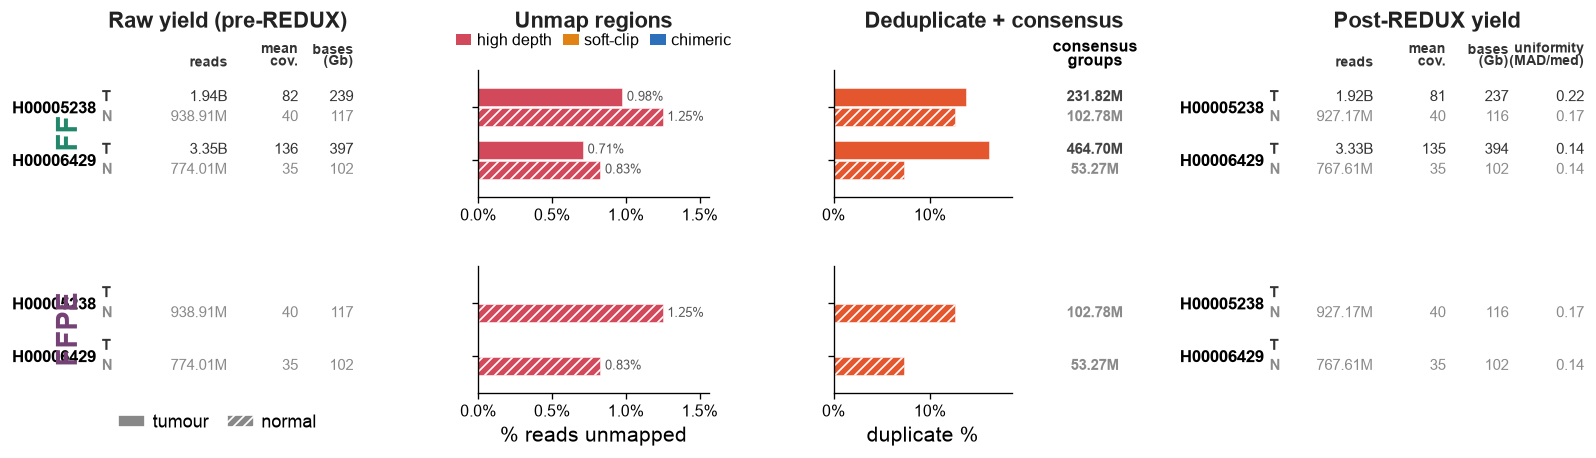

In [29]:
def _grp_y(ax, groups):
    n = len(groups); y = np.arange(n)[::-1]
    ax.set_ylim(-0.7, n - 0.3); ax.set_yticks(y)
    return y

def draw_yield_panel(ax, groups, *, phase, show_header=False):
    # Text grid of sequencing yield, tumour above and normal below per patient. phase="pre" is the
    # derived raw yield (blank without a REDUX log); phase="post" is measured, plus uniformity.
    y = _grp_y(ax, groups)
    for sp in ax.spines.values():
        sp.set_visible(False)
    ax.set_xticks([]); ax.tick_params(axis="y", length=0)
    ax.set_yticklabels([g["patient"] for g in groups], fontsize=10.2, weight="bold")
    if phase == "pre":
        cols  = [(0.50, "reads"), (0.78, "cov"), (1.00, "bases")]
        heads = [(0.50, "reads"), (0.78, "mean\ncov."), (1.00, "bases\n(Gb)")]
    else:
        cols  = [(0.33, "reads"), (0.56, "cov"), (0.76, "bases"), (1.00, "unif")]
        heads = [(0.33, "reads"), (0.56, "mean\ncov."), (0.76, "bases\n(Gb)"),
                 (1.00, "uniformity\n(MAD/med)")]
    tr = ax.get_yaxis_transform()
    for yi, g in zip(y, groups):
        for tis, off, _h in TN_ROWS:
            r = g[tis]; yy = yi + off
            col = "#333" if tis == "T" else "#8a8a8a"
            ax.text(0.0, yy, tis, va="center", ha="left", fontsize=8.8, color=col,
                    weight="bold", transform=tr)
            if not r:
                continue
            pre, post = _yield_vals(r)
            blank = (phase == "pre" and not r["log"])   # raw and post are indistinguishable
            m = pre if phase == "pre" else post
            unif = m.get("unif")
            vals = {"reads": "—" if (blank or not m.get("reads")) else human(m["reads"]),
                    "cov":   ("—" if blank else f"{m['cov']:.0f}") if m.get("cov") else "—",
                    "bases": ("—" if blank else f"{m['bases']:.0f}") if m.get("bases") else "—",
                    "unif":  f"{unif:.2f}" if (unif is not None and unif == unif) else "—"}
            for x, key in cols:
                ax.text(x, yy, vals[key], va="center", ha="right", fontsize=8.8, color=col,
                        transform=tr)
    if show_header:
        for x, lab in heads:
            ax.text(x, 1.02, lab, va="bottom", ha="right", fontsize=8.4, weight="bold",
                    color="#333", transform=ax.transAxes, linespacing=0.95)

def draw_unmap_row(ax, groups, *, xmax, show_xlabel=False):
    y = _grp_y(ax, groups); tr = ax.get_yaxis_transform()
    for yi, g in zip(y, groups):
        for tis, off, hatch in TN_ROWS:
            r = g[tis]; yy = yi + off
            if not r:
                continue
            reasons = r["log"].get("unmap_reasons", {}); tot = r["summary"].get("total_reads")
            if not tot or not reasons:
                ax.text(0.01, yy, "no log" if not r["log"] else "n/a", va="center", ha="left",
                        fontsize=7.4, color="#bbb", style="italic", transform=tr)
                continue
            left = 0.0
            for reason in UNMAP_COLORS:
                frac = reasons.get(reason, 0) / tot
                if frac > 0:
                    ax.barh(yy, frac, left=left, height=TN_H, color=UNMAP_COLORS[reason],
                            edgecolor="white", linewidth=0.3, hatch=hatch, zorder=2)
                    left += frac
            ax.text(left + xmax * 0.02, yy, f"{left:.2%}", va="center", ha="left",
                    fontsize=7.8, color="#555")
    ax.set_xlim(0, xmax); ax.tick_params(labelleft=False, labelsize=9.4)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(xmax=1, decimals=1))
    if show_xlabel:
        ax.set_xlabel("% reads unmapped")

def draw_dedup_row(ax, groups, *, xmax, show_xlabel=False):
    y = _grp_y(ax, groups); tr = ax.get_yaxis_transform()
    for yi, g in zip(y, groups):
        for tis, off, hatch in TN_ROWS:
            r = g[tis]; yy = yi + off
            if not r:
                continue
            if r["log"].get("dedup_disabled"):
                ax.text(0.02, yy, "disabled", va="center", ha="left", fontsize=7.8, color="#999",
                        style="italic", transform=tr); continue
            dp = r["summary"].get("dup_pct")
            if dp is None:
                ax.text(0.02, yy, "n/a", va="center", ha="left", fontsize=7.8, color="#999",
                        transform=tr); continue
            ax.barh(yy, dp, height=TN_H, color=DUP_CORAL, edgecolor="white", linewidth=0.3,
                    hatch=hatch, zorder=2)
    ax.set_xlim(0, xmax); ax.tick_params(labelleft=False, labelsize=9.4)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(xmax=1, decimals=0))
    if show_xlabel:
        ax.set_xlabel("duplicate %")

def draw_consensus_col(ax, groups, *, show_title=False):
    y = _grp_y(ax, groups); ax.set_xlim(0, 1); ax.axis("off"); tr = ax.get_yaxis_transform()
    for yi, g in zip(y, groups):
        for tis, off, _h in TN_ROWS:
            r = g[tis]; yy = yi + off
            if not r:
                continue
            has = bool(r["log"].get("dup_groups"))
            ax.text(0.5, yy, human(r["log"]["dup_groups"]) if has else "—", va="center",
                    ha="center", fontsize=8.8, weight="bold", transform=tr,
                    color=(("#444" if tis == "T" else "#8a8a8a") if has else "#bbb"))
    if show_title:
        ax.text(0.5, 1.0, "consensus\ngroups", ha="center", va="bottom", fontsize=9.4,
                weight="bold", transform=ax.transAxes, linespacing=1.05)

# column widths: pre-yield | gap | unmap | gap | dedup | consensus | gap | post-yield
QC_COL_W = [2.4, 0.35, 2.2, 0.35, 1.7, 0.75, 0.45, 3.0]
QC_HEADERS = [(0, 0.5, "Raw yield (pre-REDUX)"), (2, 0.5, "Unmap regions"),
              (4, 0.9, "Deduplicate + consensus"), (7, 0.5, "Post-REDUX yield")]

def draw_redux_overview(fig, spec):
    arms = list(MODALITIES)
    fracs = [_unmap_frac(g[t]) for a in arms for g in REDUX_QC[a] for t in ("T", "N") if g[t]]
    unmap_xmax = max([f for f in fracs if f == f], default=0.02) * 1.25
    dup_xmax = max((g[t]["summary"].get("dup_pct", 0) or 0 for a in arms for g in REDUX_QC[a]
                    for t in ("T", "N") if g[t]), default=0.3) * 1.15

    outer = spec.subgridspec(len(arms), 1, hspace=0.55)
    axes = {}
    for ri, arm in enumerate(arms):
        rg = outer[ri].subgridspec(1, len(QC_COL_W), width_ratios=QC_COL_W, wspace=0.30)
        col = {i: fig.add_subplot(rg[i]) for i in (0, 2, 4, 5, 7)}
        groups = REDUX_QC[arm]
        is_top, is_bot = ri == 0, ri == len(arms) - 1
        draw_yield_panel(col[0], groups, phase="pre", show_header=is_top)
        draw_unmap_row(col[2], groups, xmax=unmap_xmax, show_xlabel=is_bot)
        draw_dedup_row(col[4], groups, xmax=dup_xmax, show_xlabel=is_bot)
        draw_consensus_col(col[5], groups, show_title=is_top)
        draw_yield_panel(col[7], groups, phase="post", show_header=is_top)
        axes[arm] = col
        if is_bot:      # tumour/normal key sits under the last row, clear of the column headers
            col[0].legend(handles=[Patch(facecolor="#888", edgecolor="white", label="tumour"),
                                   Patch(facecolor="#888", edgecolor="white", hatch=HATCH,
                                         label="normal")],
                          loc="upper left", bbox_to_anchor=(0.0, -0.04), ncol=2, fontsize=10.9,
                          handlelength=1.5, columnspacing=1.0, handletextpad=0.4)
        if is_top:
            for i, x, text in QC_HEADERS:
                col[i].text(x, 1.30, text, transform=col[i].transAxes, ha="center", va="bottom",
                            fontsize=13.3, weight="bold", color="#222")
            col[2].legend(handles=[Patch(facecolor=UNMAP_COLORS[k], label=k) for k in UNMAP_COLORS],
                          loc="lower center", bbox_to_anchor=(0.5, 1.06), ncol=3, fontsize=9.4,
                          handlelength=1.0, columnspacing=0.7, handletextpad=0.35)

    fig.canvas.draw()
    for arm in arms:                                    # arm label down the left of each row
        p = axes[arm][0].get_position()
        fig.text(p.x0 - 0.020, (p.y0 + p.y1) / 2, arm, rotation=90, va="center", ha="center",
                 color=MODALITIES[arm]["color"], weight="bold", fontsize=17.2)
    return [axes[arms[0]][0]] + [axes[a][i] for a in arms for i in (0, 2, 4, 5, 7)]

fig = plt.figure(figsize=(13.5, 4.2))
draw_redux_overview(fig, fig.add_gridspec(1, 1, left=0.075, right=0.99, top=0.78, bottom=0.14)[0, 0])
plt.show()

## 7 · Panel B — SNV & indel Venn diagrams (FF vs FFPE)

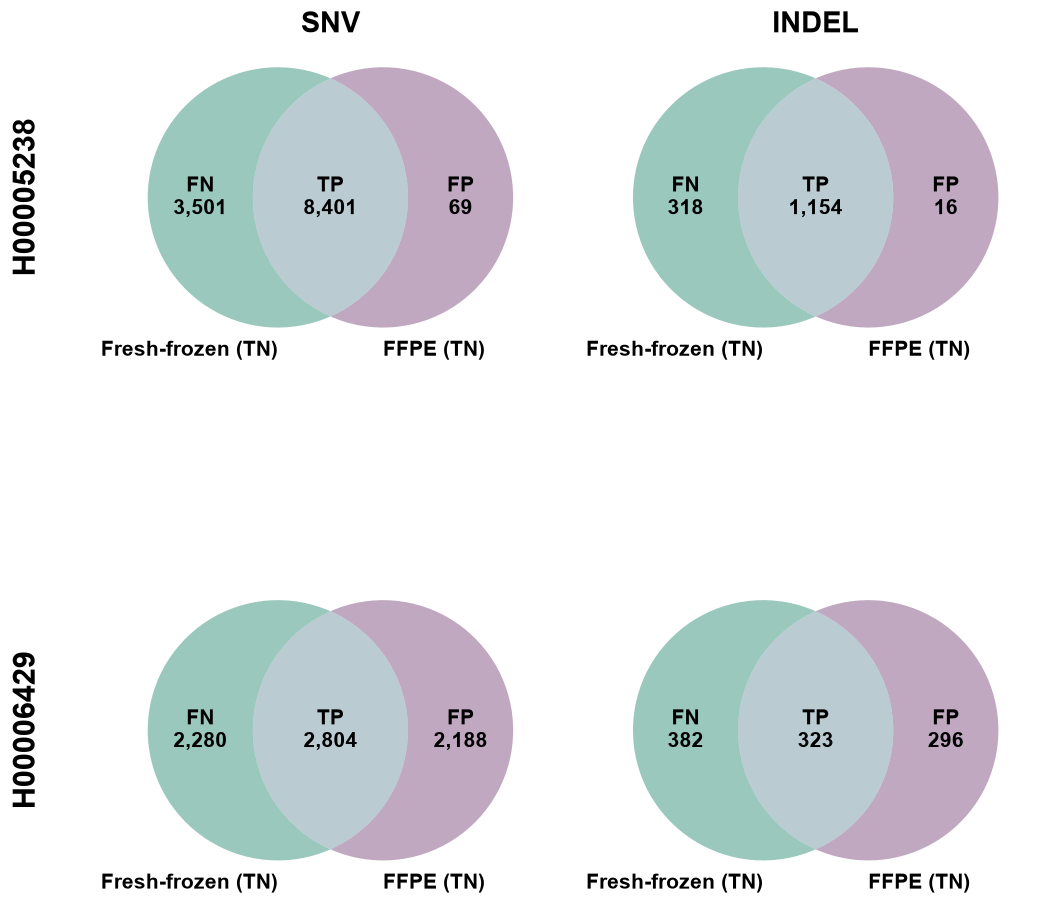

In [30]:
from matplotlib_venn import venn2
from matplotlib_venn.layout.venn2 import DefaultLayoutAlgorithm

_VENN_LAYOUT = DefaultLayoutAlgorithm(fixed_subset_sizes=(1, 1, 1))

def _draw_one_venn(ax, counts, title=None):
    tp, fn, fp = counts["TP"], counts["FN"], counts["FP"]
    # venn2 subset order = (A only, B only, AB) = (FN, FP, TP); A = FF (truth), B = FFPE (test)
    v = venn2(subsets=(fn, fp, tp),
              set_labels=(MODALITIES[TRUTH]["label"], MODALITIES[TEST]["label"]),
              set_colors=(MODALITIES[TRUTH]["color"], MODALITIES[TEST]["color"]), alpha=0.45,
              ax=ax, layout_algorithm=_VENN_LAYOUT)
    for key, val in (("10", f"FN\n{fn:,}"), ("01", f"FP\n{fp:,}"), ("11", f"TP\n{tp:,}")):
        lbl = v.get_label_by_id(key)
        if lbl:
            lbl.set_text(val); lbl.set_fontsize(12.5); lbl.set_fontweight("bold")
    for t in (v.set_labels or []):
        if t:
            t.set_fontsize(12.5); t.set_fontweight("bold")
    if title:
        ax.set_title(title, fontsize=17.2, weight="bold", pad=4)

def draw_venns(fig, spec):
    # One row per patient, columns SNV | indel.
    kinds = ("snv", "indel")
    sub = spec.subgridspec(len(PATIENTS), len(kinds), hspace=0.42, wspace=0.15)
    axes = []
    for ri, sid in enumerate(PATIENTS):
        row = []
        for ci, kind in enumerate(kinds):
            ax = fig.add_subplot(sub[ri, ci]); row.append(ax)
            counts, _, _ = benchmark_bins(kind, [sid])
            _draw_one_venn(ax, counts, title=(kind.upper() if ri == 0 else None))
        row[0].text(-0.22, 0.5, sid, transform=row[0].transAxes, rotation=90,
                    ha="center", va="center", fontsize=18.7, weight="bold")
        axes += row
    return axes

fig = plt.figure(figsize=(8.4, 4.4 * len(PATIENTS)))
draw_venns(fig, fig.add_gridspec(1, 1, left=0.08, right=0.98, top=0.92, bottom=0.06)[0, 0])
plt.show()

## 8 · Panel C — SNV mutational spectrum and allele frequency

One row per benchmark set (TP, FP, FN). Left: the SBS-96 trinucleotide profile as a fraction of that
set's SNVs, coloured by the six pyrimidine substitution classes. Right: the tumour VAF distribution
as a fraction of that set's SNVs per 0.04-wide bin — both arms for TP, FF only for FN, FFPE only for
FP. Both y-axes are shared across the three rows.

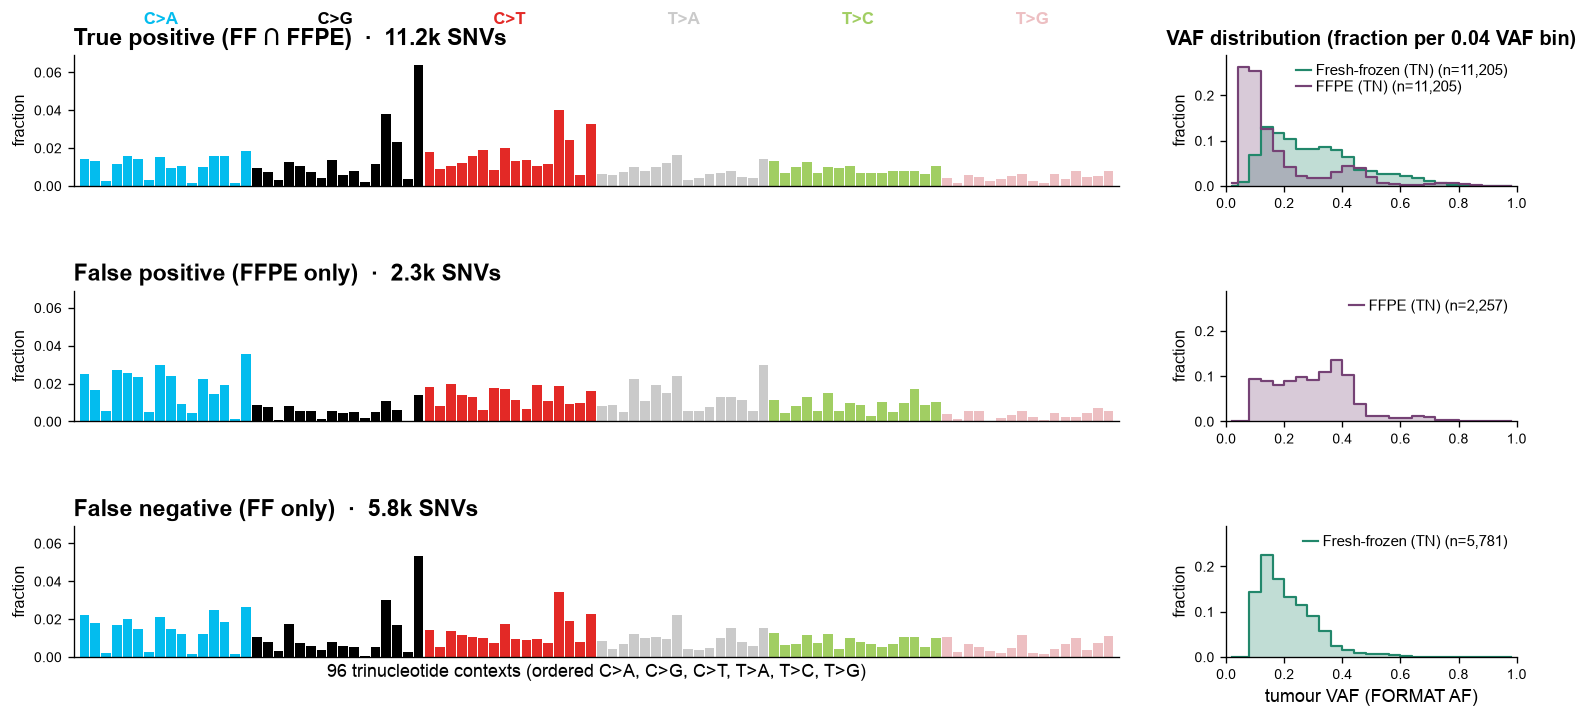

In [36]:
import matplotlib.transforms as mtransforms

VAF_BINS = np.linspace(0, 1, 26)                 # 25 bins, width 0.04
_VAF_CTR = (VAF_BINS[:-1] + VAF_BINS[1:]) / 2
_SUB_Y = 1.21
_STRIP_PT, _STRIP_H = 30, 13   # ID-83 header strip: centre height above the axes, thickness (points)

# ID-83 sections: (section name, what the per-bar number counts, first channel, last + 1).
ID83_GROUPS = [("1bp deletion", "homopolymer length", 0, 12),
               ("1bp insertion", "homopolymer length", 12, 24),
               (">1bp deletion at repeats", "repeat-unit count", 24, 48),
               (">1bp insertion at repeats", "repeat-unit count", 48, 72),
               ("microhomology deletion", "microhomology length", 72, 83)]
ID83_BOUNDS = [12, 24, 48, 72]
ID83_SECTION_LABEL = {"1bp deletion": "1bp\ndeletion", "1bp insertion": "1bp\ninsertion",
                      ">1bp deletion at repeats": ">1bp deletion\nat repeats",
                      ">1bp insertion at repeats": ">1bp insertion\nat repeats",
                      "microhomology deletion": "microhomology\ndeletion"}

def _vaf_frac(values):
    v = np.array([x for x in values if x is not None and not np.isnan(x)])
    if v.size == 0:
        return None, 0
    counts, _ = np.histogram(v, bins=VAF_BINS)
    return counts / v.size, int(v.size)

def _snv_bands(ax):
    for ci, cls in enumerate(SBS_CLASSES):
        ax.text((ci + 0.5) / 6, _SUB_Y, cls, transform=ax.transAxes, ha="center", va="bottom",
                fontsize=10, weight="bold", color=(SBS_COLORS[cls] if cls != "C>G" else "#000"))

def _id83_bands(ax):
    # COSMIC-style header above the row title: a coloured strip per sub-block (base C/T or indel
    # size), section names above it. Heights are in points so the title never runs into it.
    # What the per-bar number counts is written below the x-axis of the last row (_id83_xmeanings).
    xdata_yaxes = mtransforms.blended_transform_factory(ax.transData, ax.transAxes)
    above = lambda pts: mtransforms.offset_copy(xdata_yaxes, fig=ax.figure, y=pts, units="points")
    subs = [("C", 0, 6), ("T", 6, 12), ("C", 12, 18), ("T", 18, 24),
            ("2", 24, 30), ("3", 30, 36), ("4", 36, 42), ("5+", 42, 48),
            ("2", 48, 54), ("3", 54, 60), ("4", 60, 66), ("5+", 66, 72),
            ("2", 72, 73), ("3", 73, 75), ("4", 75, 78), ("5+", 78, 83)]
    for name, a, b in subs:
        col = id83_color(ID83_CHANNELS[a])
        ax.plot([a - 0.4, b - 0.6], [1, 1], transform=above(_STRIP_PT), color=col, lw=_STRIP_H,
                solid_capstyle="butt", clip_on=False)
        light = np.dot(mpl.colors.to_rgb(col), (0.299, 0.587, 0.114)) > 0.6
        ax.text((a + b - 1) / 2, 1, name, transform=above(_STRIP_PT), ha="center", va="center",
                fontsize=8.4, weight="bold", color=("#333" if light else "white"))
    for name, _meaning, a, b in ID83_GROUPS:
        ax.text((a + b - 1) / 2, 1, ID83_SECTION_LABEL[name], transform=above(_STRIP_PT + _STRIP_H / 2 + 3),
                ha="center", va="bottom", fontsize=9.7, weight="bold", color="#333", linespacing=1.0)

def _id83_xmeanings(ax):
    # Adjacent sections that count the same thing share one label (both 1bp sections count
    # homopolymer length); a single label per section no longer fits at the current font size.
    n = len(ID83_CHANNELS)
    spans = []
    for _name, meaning, a, b in ID83_GROUPS:
        if spans and spans[-1][0] == meaning and spans[-1][2] == a:
            spans[-1][2] = b
        else:
            spans.append([meaning, a, b])
    for meaning, a, b in spans:
        ax.text((a + b) / 2 / n, -0.40, meaning.replace(" length", "\nlength") if b - a < 20 else meaning,
                transform=ax.transAxes, ha="center", va="top", fontsize=9.4, weight="bold", color="#333")

def _id83_xticklabels():
    labs = []
    for ch in ID83_CHANNELS:
        sz, typ, cat, i = ch.split(":"); i = int(i)
        if cat == "M":
            labs.append(str(i))                              # microhomology length (bp)
        elif sz == "1" and typ == "Del":
            labs.append("6+" if i == 5 else str(i + 1))      # homopolymer length 1..6+
        else:
            labs.append("5+" if i == 5 else str(i))          # repeat-unit count / copies 0..5+
    return labs

def draw_profiles(fig, spec, kind):
    channels = CHANNELS[kind]
    counts, prof, vafs = BENCH[kind]
    if kind == "snv":
        colors = [SBS_COLORS[b.split("_")[0]] for b in channels]; bands = _snv_bands
        noun = "SNVs"
        xlab = "96 trinucleotide contexts (ordered C>A, C>G, C>T, T>A, T>C, T>G)"
    else:
        colors = [id83_color(ch) for ch in channels]; bands = _id83_bands
        noun = "indels"
        xlab = "COSMIC ID-83 indel channels"

    fracs = {r: (prof[r] / prof[r].sum() if prof[r].sum() else prof[r]) for r in BENCH_REGIONS}
    ymax = max((f.max() for f in fracs.values() if f.size and f.max() > 0), default=1.0)
    vaf_h = {r: {a: _vaf_frac(vafs[r][a]) for a in BENCH_ARMS[r]} for r in BENCH_REGIONS}
    vmax = max((float(f.max()) for r in BENCH_REGIONS for f, _ in vaf_h[r].values()
                if f is not None), default=1.0)

    sub = spec.subgridspec(len(BENCH_REGIONS), 2, width_ratios=[3.6, 1.0], hspace=0.80, wspace=0.16)
    axes = []
    for r, region in enumerate(BENCH_REGIONS):
        axp = fig.add_subplot(sub[r, 0]); axes.append(axp)
        tot = prof[region].sum()
        axp.bar(range(len(channels)), fracs[region], width=0.9, color=colors, linewidth=0)
        axp.set_xlim(-1, len(channels)); axp.set_xticks([]); axp.set_ylim(0, ymax * 1.08)
        if kind == "indel":
            for bnd in ID83_BOUNDS:
                axp.axvline(bnd - 0.5, color="#BBBBBB", lw=0.7, zorder=1)
        axp.set_ylabel("fraction", fontsize=9.4); axp.tick_params(axis="y", labelsize=8.6)
        axp.set_title(f"{BENCH_LABEL[region]}  ·  {fmt(tot)} {noun}", loc="left",
                      fontsize=14, weight="bold")
        if tot == 0:
            axp.text(0.5, 0.5, f"no {noun}", transform=axp.transAxes, ha="center", va="center",
                     fontsize=10.9, color="#999")
        if r == 0:
            bands(axp)

        axv = fig.add_subplot(sub[r, 1]); axes.append(axv)
        for a in BENCH_ARMS[region]:
            frac, n = vaf_h[region][a]
            if frac is None:
                continue
            col = MODALITIES[a]["color"]
            axv.fill_between(_VAF_CTR, frac, step="mid", color=col, alpha=0.28, lw=0)
            axv.step(_VAF_CTR, frac, where="mid", color=col, lw=1.3,
                     label=f"{MODALITIES[a]['label']} (n={n:,})")
        axv.set_xlim(0, 1); axv.set_ylim(0, vmax * 1.1)
        axv.set_ylabel("fraction", fontsize=9.4); axv.tick_params(axis="both", labelsize=8.6)
        axv.legend(fontsize=9, loc="upper right", handlelength=1.0, handletextpad=0.3,
                   labelspacing=0.15, borderaxespad=0.2)
        if r == 0:
            axv.set_title("VAF distribution (fraction per 0.04 VAF bin)", fontsize=11.8, weight="bold")
        if r == len(BENCH_REGIONS) - 1:
            if kind == "indel":
                axp.set_xticks(range(len(channels)))
                axp.set_xticklabels(_id83_xticklabels(), fontsize=6.7)
                axp.tick_params(axis="x", length=1.5, pad=1)
                _id83_xmeanings(axp)
                axp.text(0.5, -0.66, xlab, transform=axp.transAxes, ha="center", va="top",
                         fontsize=10.9, weight="bold")
            else:
                axp.set_xlabel(xlab, fontsize=10.9)
            axv.set_xlabel("tumour VAF (FORMAT AF)", fontsize=10.9)
    return axes

fig = plt.figure(figsize=(13.0, 6.6))
draw_profiles(fig, fig.add_gridspec(1, 1, left=0.045, right=0.97, top=0.86, bottom=0.10)[0, 0], "snv")
plt.show()

## 9 · Panel D — indel mutational spectrum and allele frequency

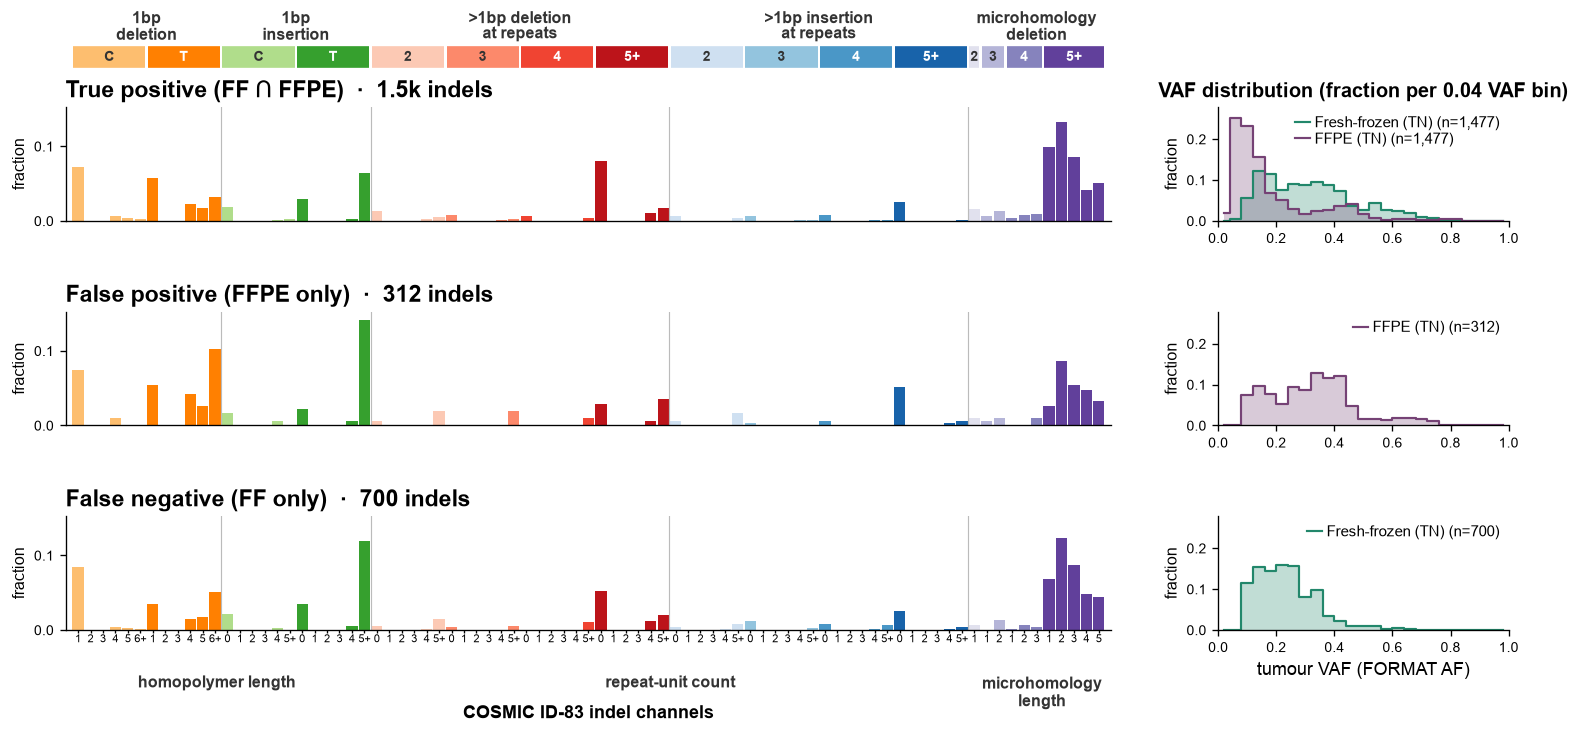

In [37]:
fig = plt.figure(figsize=(13.0, 6.6))
draw_profiles(fig, fig.add_gridspec(1, 1, left=0.045, right=0.97, top=0.82, bottom=0.16)[0, 0], "indel")
plt.show()

## 10 · Composite figure

Wrote: figures/extended_figure_4.pdf figures/extended_figure_4.svg figures/extended_figure_4.png


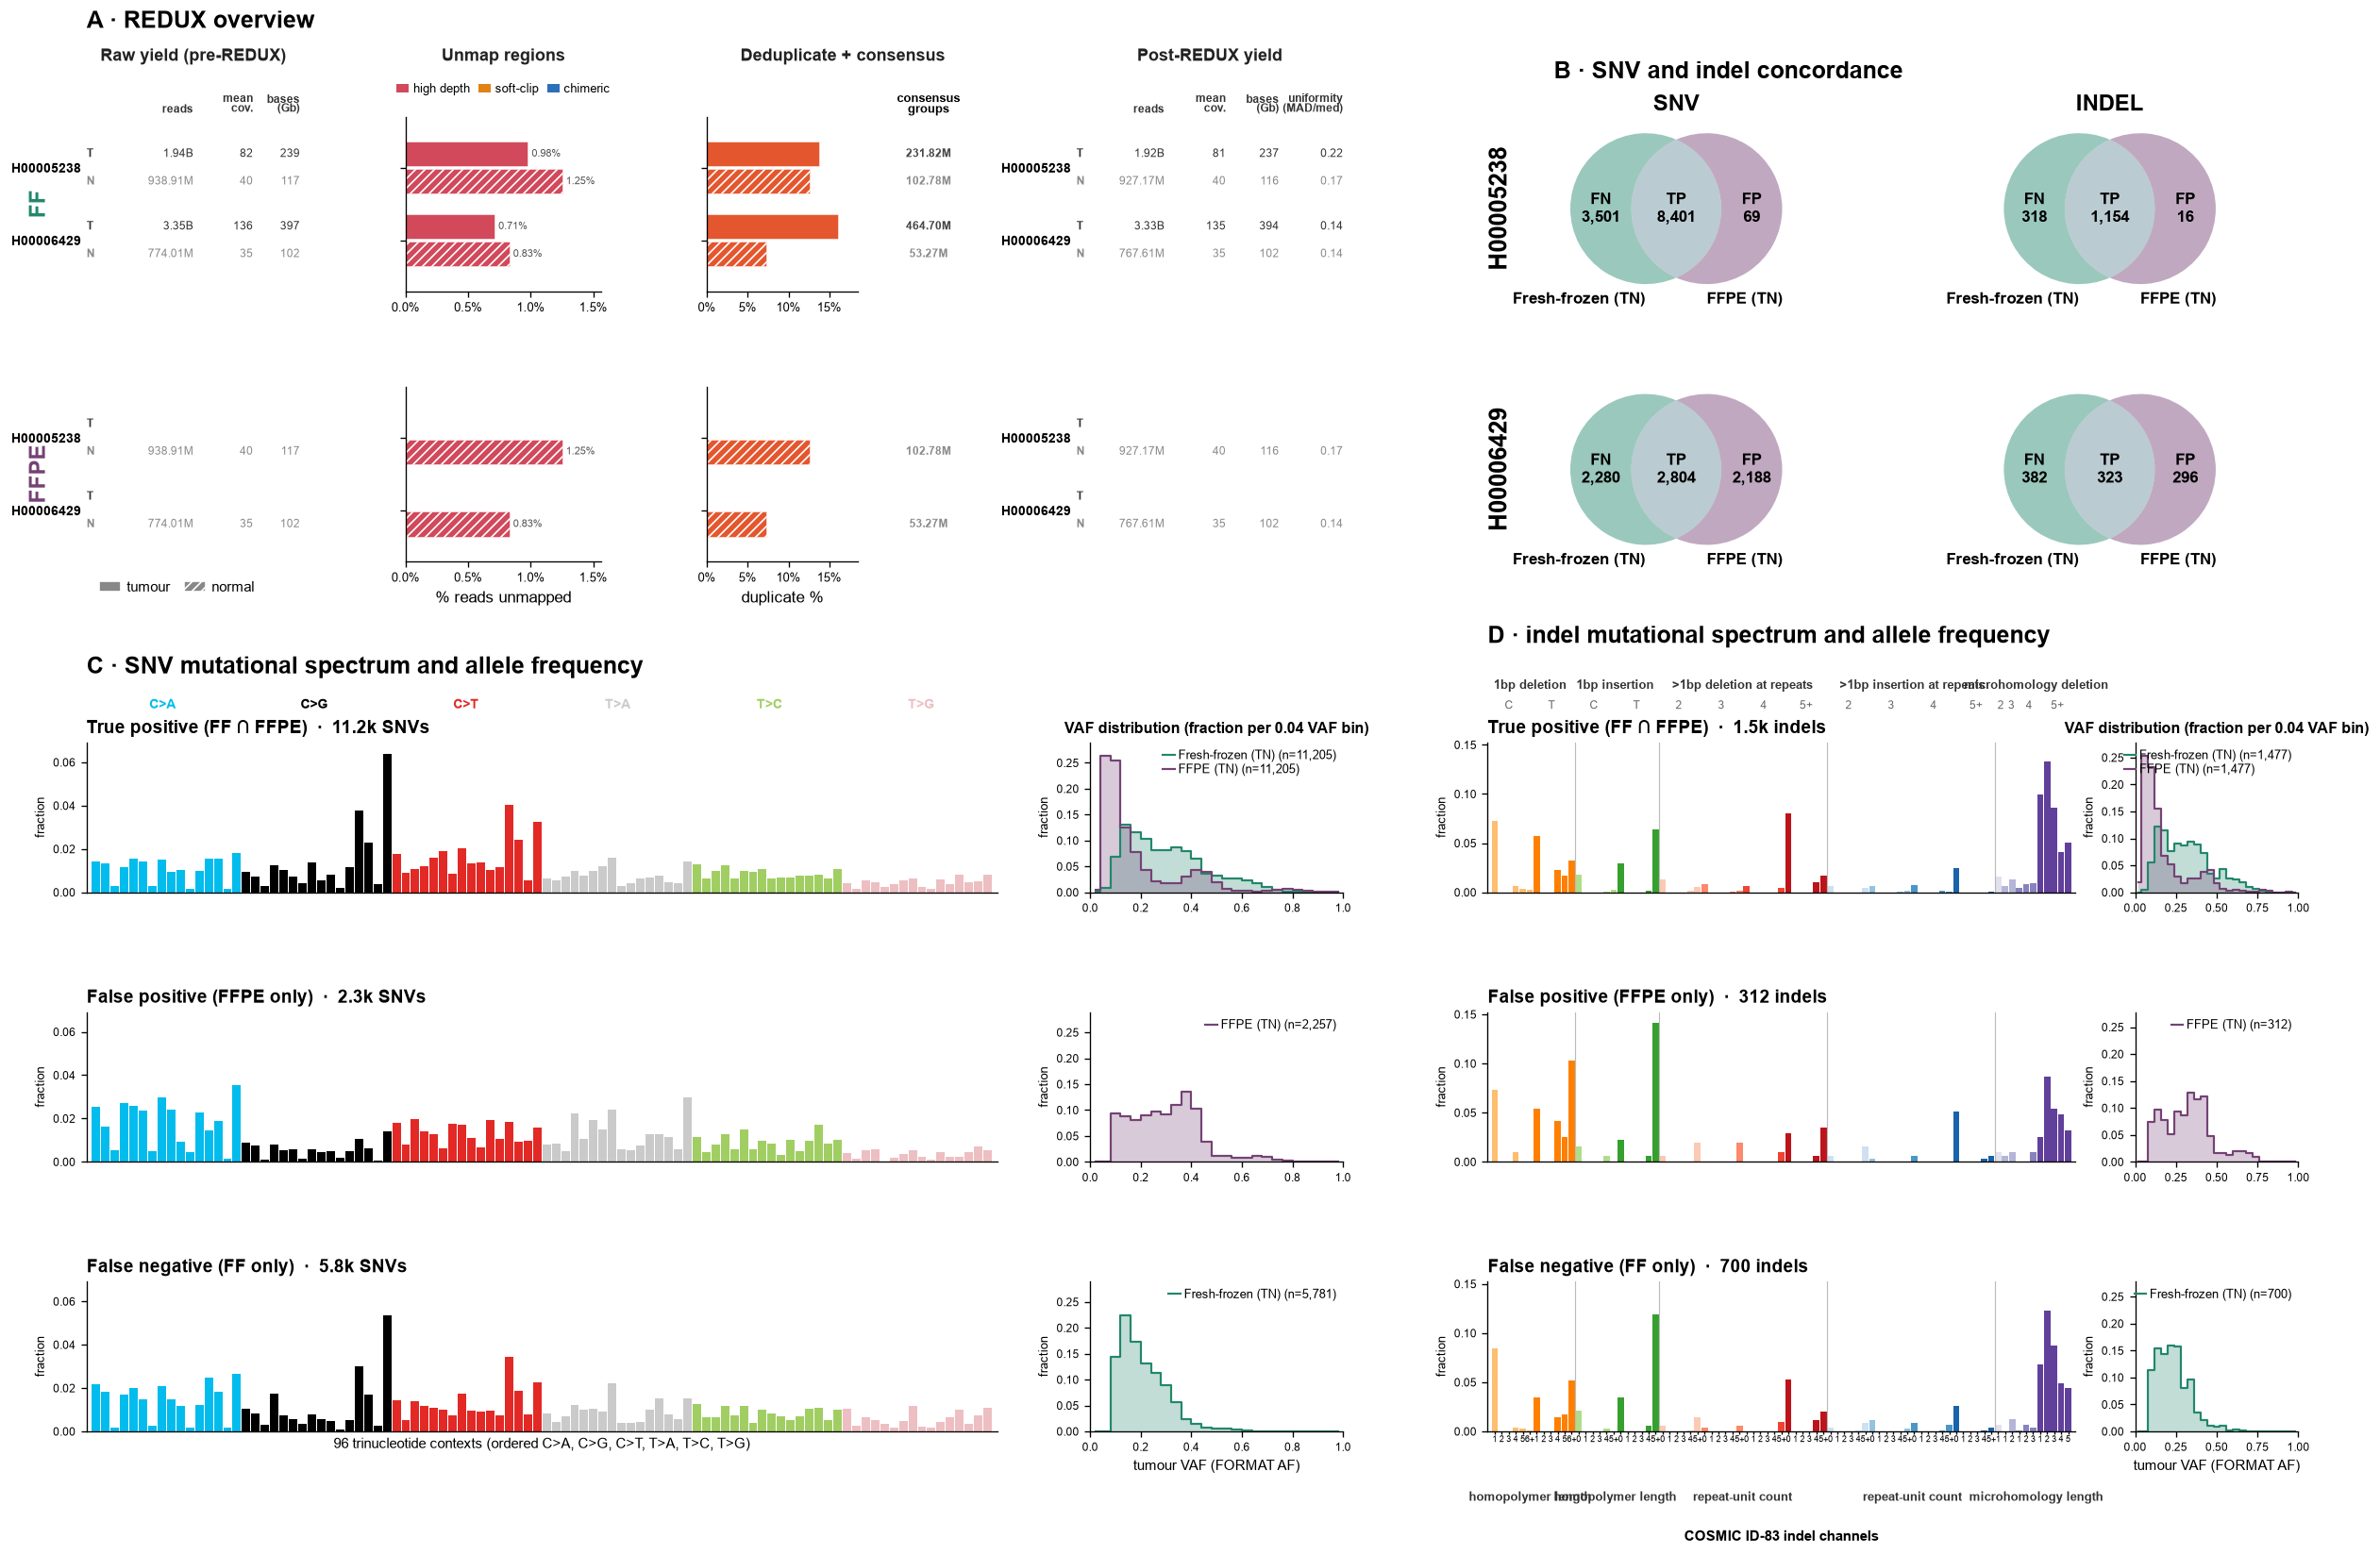

In [23]:
def composite_figure():
    fig = plt.figure(figsize=(21.0, 13.5))
    outer = fig.add_gridspec(2, 2, width_ratios=[1.55, 1.0], height_ratios=[1.0, 1.55],
                             hspace=0.32, wspace=0.14,
                             left=0.045, right=0.975, top=0.905, bottom=0.045)
    axA = draw_redux_overview(fig, outer[0, 0])
    axB = draw_venns(fig, outer[0, 1])
    axC = draw_profiles(fig, outer[1, 0], "snv")
    axD = draw_profiles(fig, outer[1, 1], "indel")

    fig.canvas.draw()
    for group, text, dy in ((axA, "A · REDUX overview", 0.055),
                            (axB, "B · SNV and indel concordance", 0.022),
                            (axC, "C · SNV mutational spectrum and allele frequency", 0.042),
                            (axD, "D · indel mutational spectrum and allele frequency", 0.075)):
        p = group[0].get_position()
        fig.text(p.x0, p.y1 + dy, text, fontsize=18, weight="bold", ha="left", va="bottom")
    return fig

fig = composite_figure()
stem = EXPORT_DIR / "extended_figure_4"
for ext in ("pdf", "svg", "png"):
    fig.savefig(f"{stem}.{ext}", bbox_inches="tight")
print("Wrote:", *(f"{stem}.{e}" for e in ("pdf", "svg", "png")))
plt.show()